# Group performance — success rate, RT, ET and MD

The group version of `performance.ipynb`. Writes into `figures/group/performance/`:

| file | contents |
|---|---|
| `01_success_rate.png` … `04_mean_deviation.png` | learning curves, one point per block per chord |
| `…_pooled.png` | the same with Test 1 and Test 2 each collapsed to one point per chord |
| `05_tests_by_chord.png` | Test 1 → Test 2 → end of 4-finger practice, every subject shown |

**How a group point is made.** Each subject is first summarised exactly as in their own
figures: the proportion correct for success rate, the **median** of correct trials for
RT, ET and MD (they are right-skewed, see `performance.ipynb`). The group point is the
**mean of those per-subject values**, and the bar is **±1 SEM across subjects**, so the
error bar describes between-subject variability, not trial noise.

**s100 is included for days 1–3 only.** It was the 3-day pilot and stopped after Test 2
(block 38), so blocks 1–38 average 5 subjects and the 4-finger training blocks 39–52
average 4. That is part of the design, not missing data.

Some points still rest on fewer subjects than the design allows, for two reasons:
- the trial order is shuffled in pairs, so a 4-finger chord is occasionally **not presented
  at all** in a block for a subject (15 subject-blocks across the group);
- a subject with no correct trial of a chord has no RT/ET/MD there (s102 and s103 never got
  the ring+pinky chords in Test 1).

Those points are drawn with **open markers**.

Same x-axis as the single-subject figures (`utils/timeline.py`). Reads `analysis/s<sn>.csv`.

## Imports

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D

# project root = the folder that contains target/ and data/
ROOT = Path.cwd()
while not (ROOT / "target").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from utils import timeline
from utils.chords import ChordRoles
from utils.design import LAST_BLOCK, SEGMENTS, TEST1_BLOCKS, TEST2_BLOCKS, day_of_block

SUBJECTS = [100, 101, 102, 103, 104]   # <<< s100 is the 3-day pilot: it only contributes to blocks 1-38

ANALYSIS_DIR = ROOT / "analysis"
FIG_DIR = ROOT / "figures" / "group" / "performance"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="ticks", context="notebook",
              rc={"axes.spines.top": False, "axes.spines.right": False})

df = pd.concat([pd.read_csv(ANALYSIS_DIR / f"s{sn}.csv") for sn in SUBJECTS], ignore_index=True)
# s102 block 1 TN 20 is a truncated .dat row (no outcome recorded): it cannot be scored
df = df[df.trialPoint.notna()]
COLLECTED = set(df.BN.unique())
N_SUBJ = len(SUBJECTS)
SUBJ_TXT = ", ".join(f"s{sn}" for sn in SUBJECTS)
DESIGN = {sn: set(day_of_block(sn)) for sn in SUBJECTS}     # blocks each subject was meant to run


def n_expected(blocks):
    """How many subjects' designs include these blocks (s100 stops at block 38)."""
    return sum(set(blocks) <= DESIGN[sn] for sn in SUBJECTS)


N_TXT = " / ".join(dict.fromkeys(  # e.g. "5 (blocks 1-38) / 4 (blocks 39-52)"
    f"{n_expected([b])}" for b in sorted(set().union(*DESIGN.values()))))
SHORT = {sn: LAST_BLOCK[sn] for sn in SUBJECTS if sn in LAST_BLOCK}
SHORT_TXT = "; ".join(f"s{sn} through block {b} only" for sn, b in SHORT.items())

print(df.groupby("sn").agg(trials=("TN", "size"), last_block=("BN", "max"),
                           success=("trialPoint", "mean")).round(3).to_string())

     trials  last_block  success
sn                              
100     760          38    0.942
101    1040          52    0.982
102    1039          52    0.655
103    1040          52    0.853
104    1040          52    0.905


## Chord roles

Built per subject from the data (`utils/chords.py`). The group figures key on chord ID, so
every subject must have the same trained and tested chords; this is checked here. If a
future counterbalancing group uses different chords, group by `roles.role(chord)` instead.

In [2]:
train_blocks = [b for s in SEGMENTS if s["kind"] == "2f" for b in s["blocks"]]
test_blocks = [b for s in SEGMENTS if s["kind"] == "4f" for b in s["blocks"]]

roles_of = {sn: ChordRoles(trained=d.loc[d.BN.isin(train_blocks), "chordID"].unique(),
                           tested=d.loc[d.BN.isin(test_blocks), "chordID"].unique())
            for sn, d in df.groupby("sn")}
roles = roles_of[SUBJECTS[0]]
assert all(r.trained == roles.trained and r.tested == roles.tested for r in roles_of.values()), \
    "subjects differ in their chord set - group by role, not chord ID"

TESTED, TRAINED = roles.tested, roles.trained        # tested: both -> 1st -> 2nd -> neither
LABEL, COLOR, MARKER = roles.label, roles.color, roles.marker
for c in TESTED + TRAINED:
    print(f"  {LABEL[c]}")

  12912  both components trained
  12921  1st component trained
  21912  2nd component trained
  21921  neither component trained
  12999  trained component (1st)
  99912  trained component (2nd)


## Per-subject values and the group summary

`per_subject(blocks, chord, meas)` gives one value per subject, summarising that chord's
trials over `blocks` the way the single-subject figures do. `group(vals)` turns those into
the mean, SEM and number of contributing subjects.

The per-block subject values are also saved to `analysis/group_performance.csv` for stats.

In [3]:
MEASURES = [
    dict(col="trialPoint", fname="01_success_rate.png",
         ylabel="Success rate (% of trials correct)", short="Success rate (%)",
         title="Chord success rate across learning",
         note="All trials included; a plan error counts as a failed trial. "
              "Per subject: % correct.",
         correct_only=False, scale=100),
    dict(col="RT", fname="02_reaction_time.png",
         ylabel="Reaction time (ms)", short="RT (ms)",
         title="Reaction time across learning",
         note="Correct trials only. RT = go cue → first finger leaves the baseline zone. "
              "Per subject: median.",
         correct_only=True, scale=1),
    dict(col="ET", fname="03_execution_time.png",
         ylabel="Execution time (ms)", short="ET (ms)",
         title="Execution time across learning",
         note="Correct trials only. ET = first movement → onset of the successful hold. "
              "Per subject: median.",
         correct_only=True, scale=1),
    dict(col="MD", fname="04_mean_deviation.png",
         ylabel="Mean deviation (a.u.)", short="MD (a.u.)",
         title="Mean deviation across learning",
         note="Correct trials only. Lower = more simultaneous. Per subject: median.",
         correct_only=True, scale=1),
]
GROUP_NOTE = (f"  Group: mean of per-subject values ± SEM across subjects (n = {N_TXT}"
              + (f"; {SHORT_TXT}" if SHORT else "") + "); open markers = a subject is missing "
              "(chord not presented in that block, or no correct trial).")


def per_subject(blocks, chord, meas):
    """One value per subject for `chord` over `blocks` (index = sn, missing subjects dropped)."""
    d = df[df.BN.isin(blocks) & (df.chordID == chord)]
    if meas["correct_only"]:
        d = d[d.trialPoint == 1]
    v = d.dropna(subset=[meas["col"]]).groupby("sn")[meas["col"]]
    out = v.mean() if meas["col"] == "trialPoint" else v.median()
    return meas["scale"] * out


def group(vals, blocks):
    """(mean, SEM, n, full) across subjects. `full` is False when fewer subjects contribute
    than the design allows for `blocks`; SEM is 0 when only one subject contributes."""
    n = len(vals)
    if n == 0:
        return np.nan, np.nan, 0, False
    sem = vals.std(ddof=1) / np.sqrt(n) if n > 1 else 0.0
    return vals.mean(), sem, n, n == n_expected(blocks)


# per-block subject values, for anyone who wants to run stats on them
rows = []
for meas in MEASURES:
    for b in sorted(COLLECTED):
        for c in sorted(df.loc[df.BN == b, "chordID"].unique()):
            for sn, v in per_subject([b], c, meas).items():
                rows.append(dict(measure=meas["col"], sn=sn, BN=b, chordID=c, value=v))
table = pd.DataFrame(rows)
table.to_csv(ANALYSIS_DIR / "group_performance.csv", index=False)
print(f"{len(table)} rows -> analysis/group_performance.csv")

2514 rows -> analysis/group_performance.csv


## Learning curves

Same layout as the single-subject figures: one point per block per chord (or per test,
in the `_pooled` versions), the days separated, the 4-finger segments shaded.

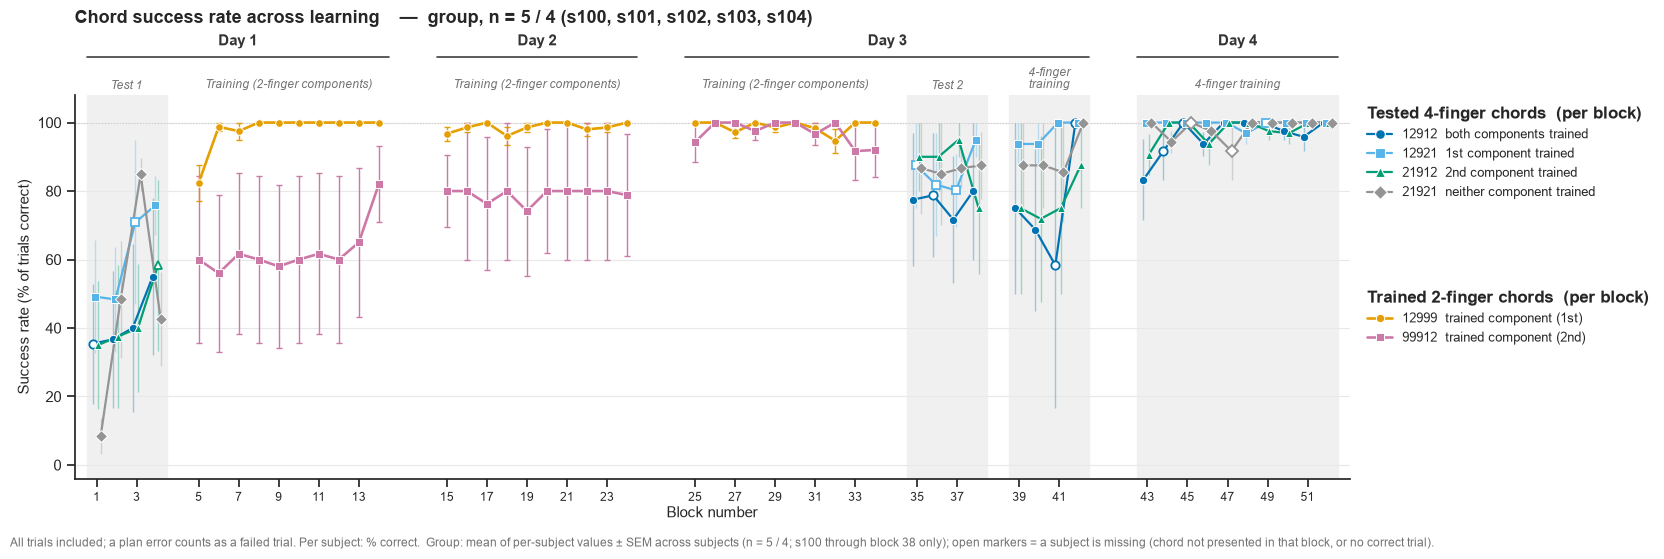

wrote figures/group/performance/01_success_rate.png


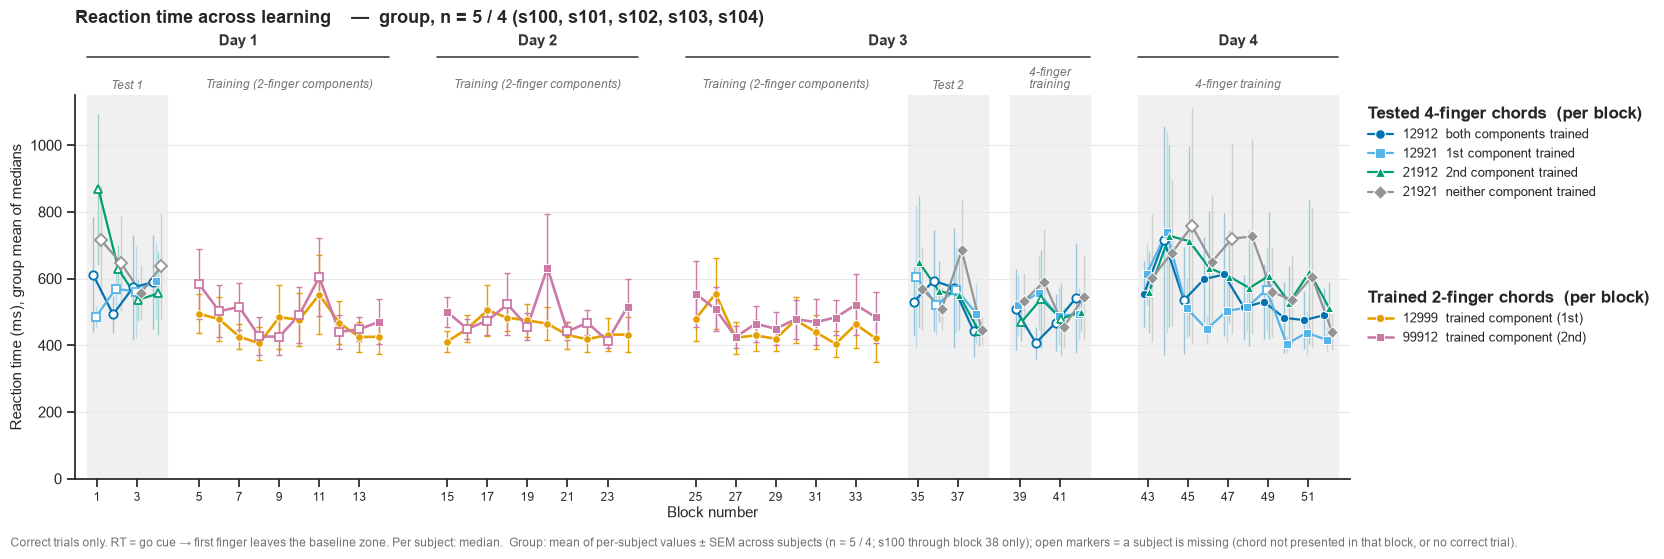

wrote figures/group/performance/02_reaction_time.png


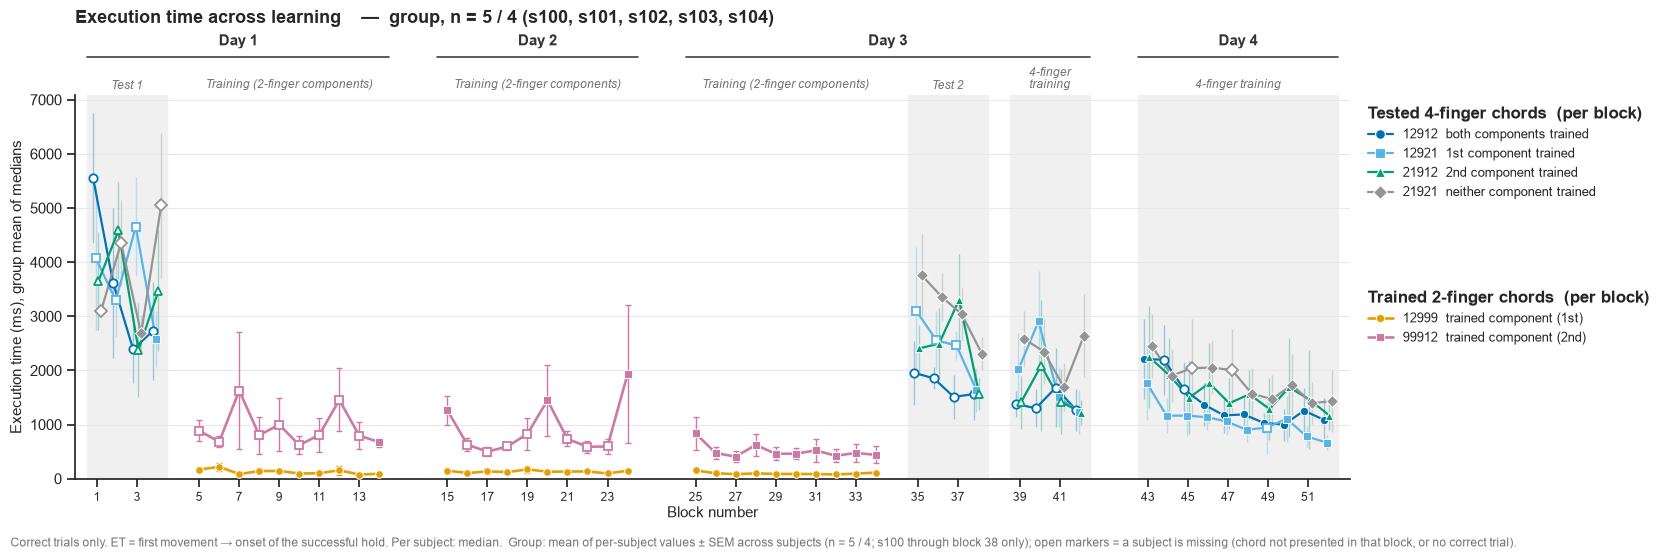

wrote figures/group/performance/03_execution_time.png


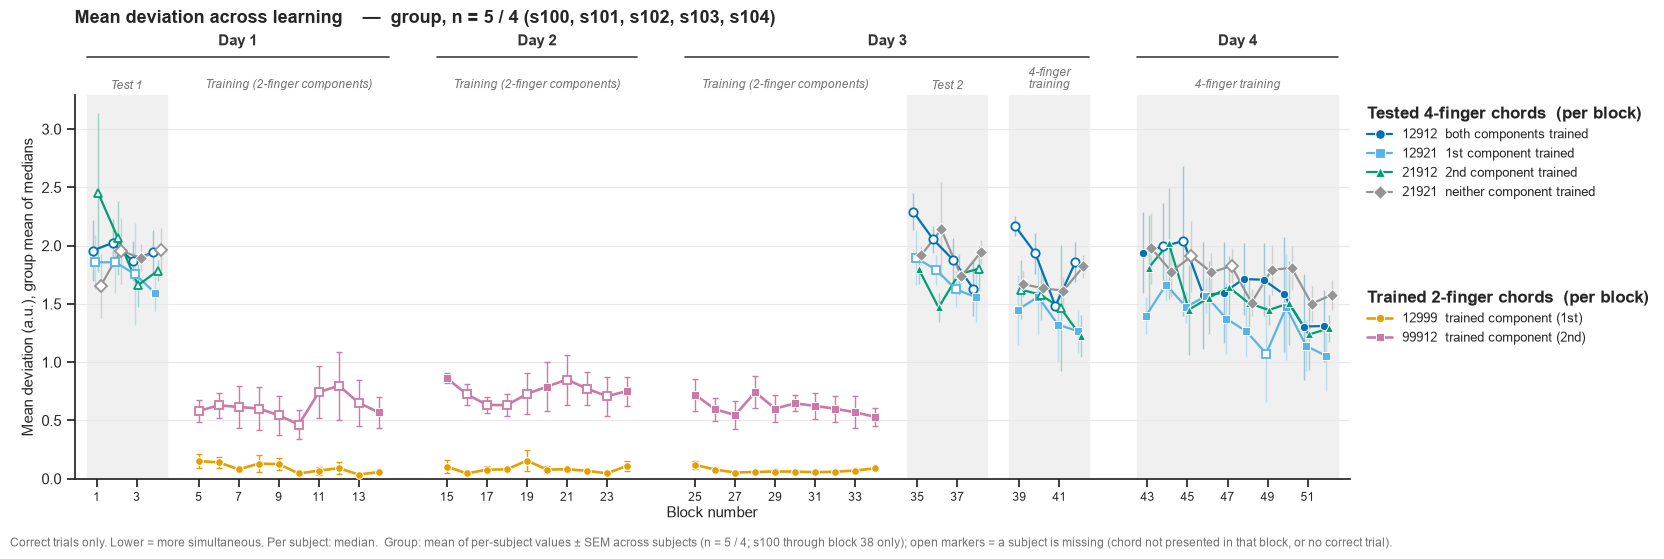

wrote figures/group/performance/04_mean_deviation.png


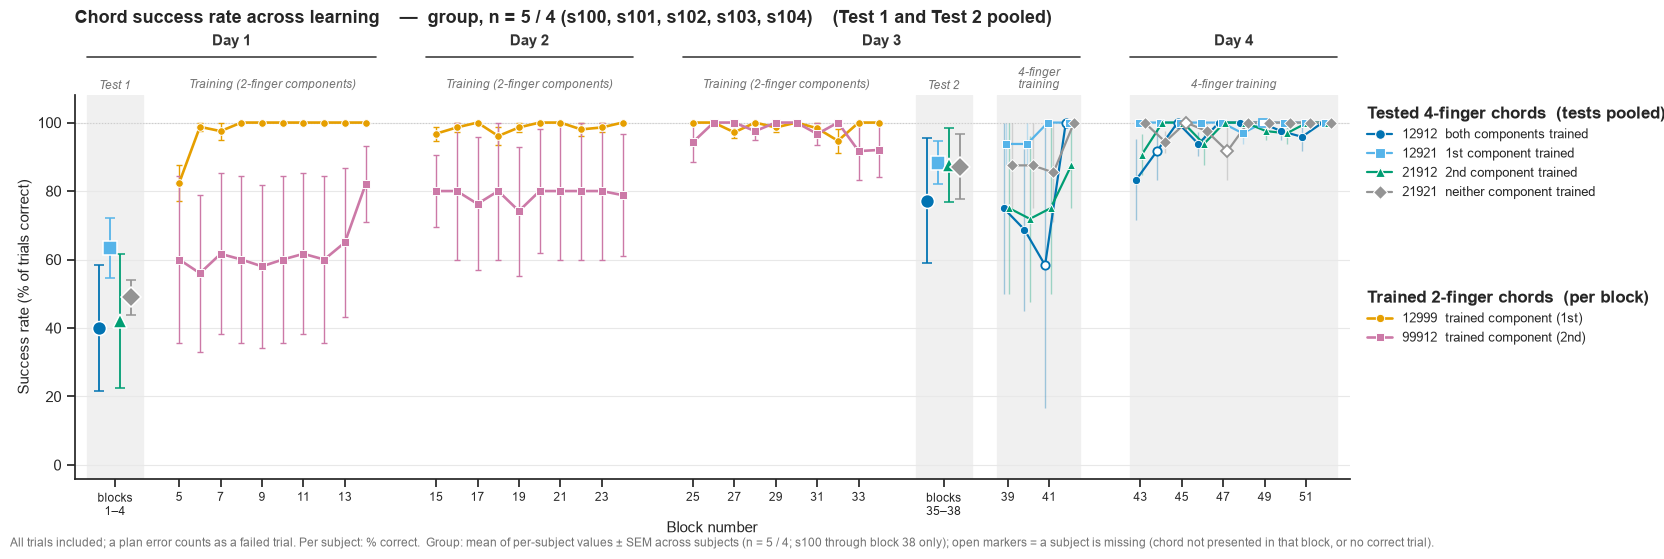

wrote figures/group/performance/01_success_rate_pooled.png


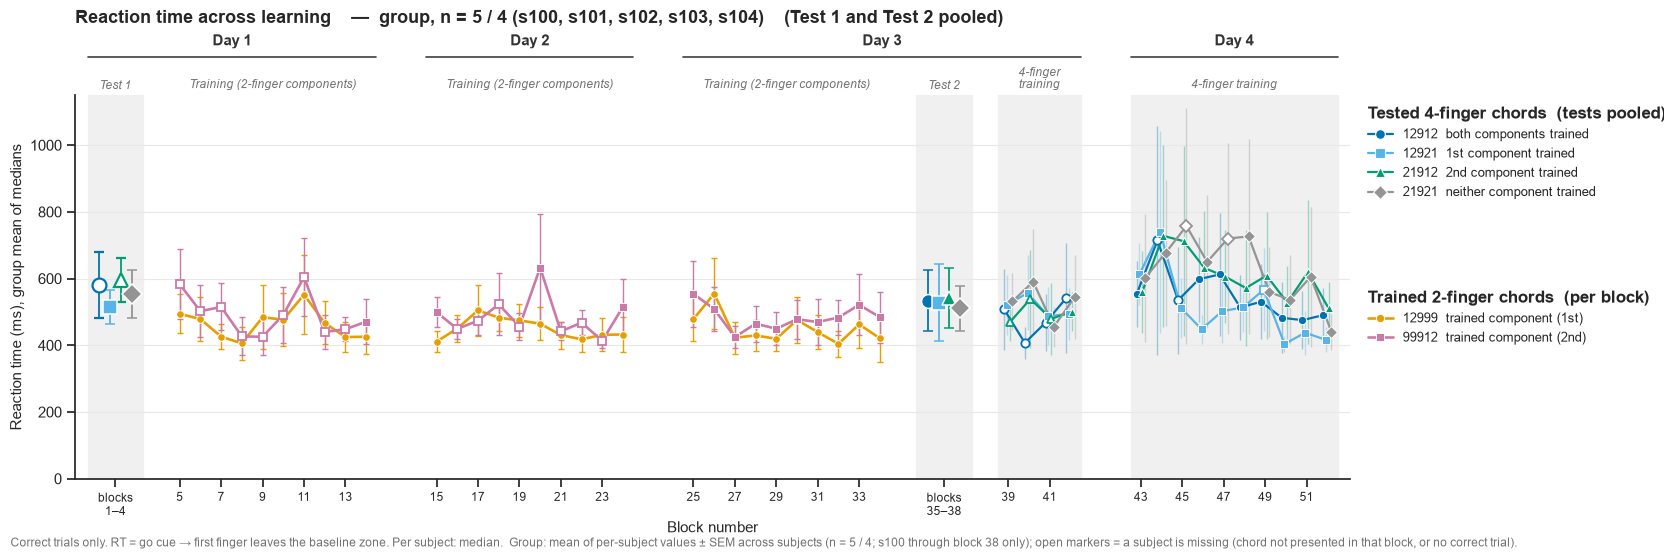

wrote figures/group/performance/02_reaction_time_pooled.png


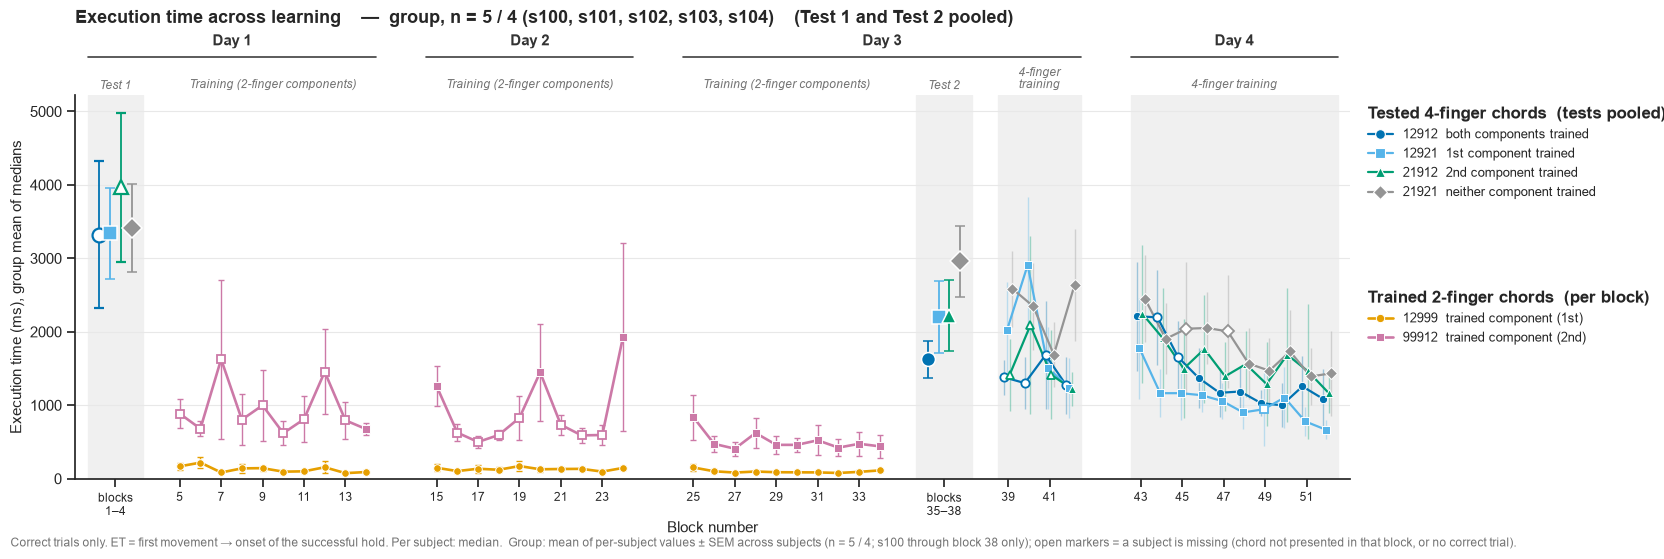

wrote figures/group/performance/03_execution_time_pooled.png


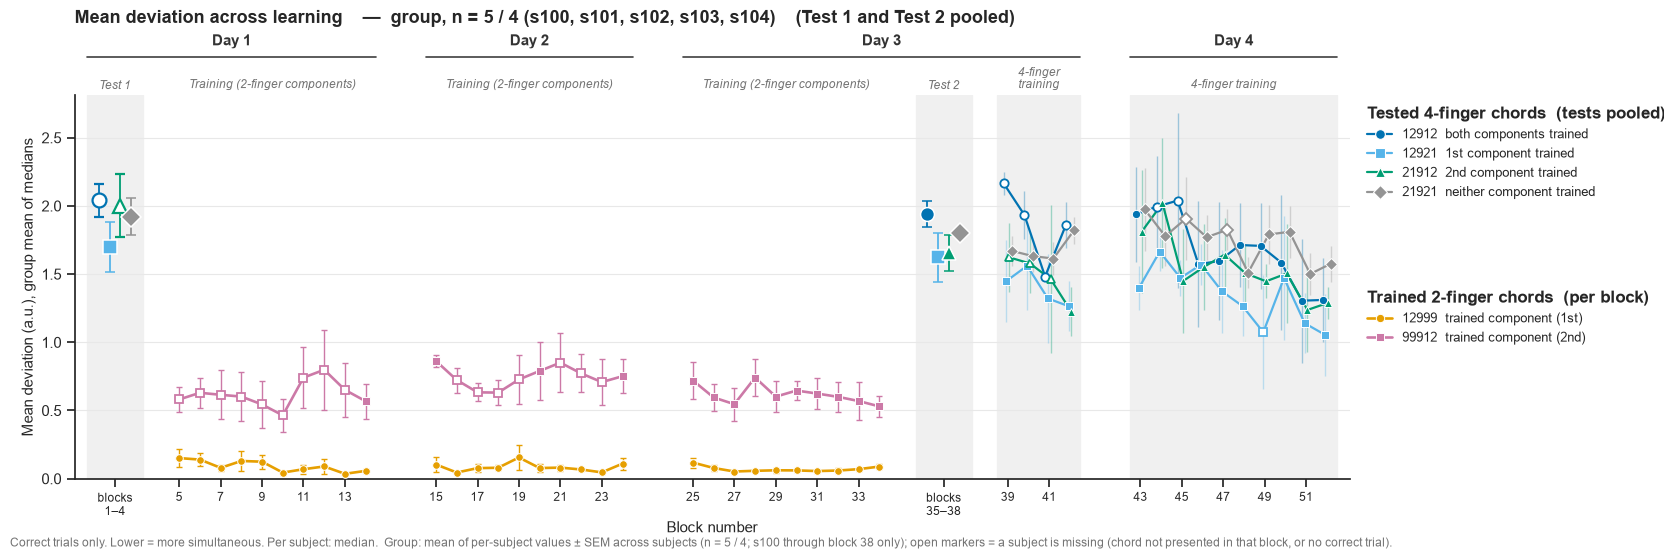

wrote figures/group/performance/04_mean_deviation_pooled.png


In [4]:
dodge = dict(zip(TESTED, np.linspace(-0.2, 0.2, len(TESTED))))
dodge_pooled = dict(zip(TESTED, np.linspace(-0.78, 0.78, len(TESTED))))


for pool_tests, meas in [(p, m) for p in (False, True) for m in MEASURES]:
    segs = timeline.layout(pool_tests)
    fname = meas["fname"].replace(".png", "_pooled.png") if pool_tests else meas["fname"]
    fig, ax = plt.subplots(figsize=(17, 5.9))

    timeline.draw_background(ax, segs, COLLECTED)

    # pooled tests: one point per chord over all of the segment's blocks
    for seg in segs:
        if not seg["pooled"]:
            continue
        for c in TESTED:
            m, e, n, full = group(per_subject(seg["blocks"], c, meas), seg["blocks"])
            if n == 0:
                continue
            ax.errorbar(seg["center"] + dodge_pooled[c], m, yerr=e, color=COLOR[c],
                        marker=MARKER[c], ms=10, lw=0, capsize=3.5, elinewidth=1.3,
                        mfc=COLOR[c] if full else "white", mec="white" if full else COLOR[c],
                        mew=1.1 if full else 1.6, zorder=4)

    # everything else: one point per block per chord; lines join the blocks of a segment
    for seg in segs:
        if seg["pooled"]:
            continue
        four = seg["kind"] == "4f"
        for c in (TESTED if four else TRAINED):
            pts = [(seg["x"][b] + (dodge[c] if four else 0), *group(per_subject([b], c, meas), [b]))
                   for b in seg["blocks"]]
            pts = [p for p in pts if p[3] > 0]
            if not pts:
                continue
            xs, ys, es, ns, full = map(np.array, zip(*pts))
            eb = ax.errorbar(xs, ys, yerr=es, color=COLOR[c], marker="none",
                             lw=1.6 if four else 1.9, capsize=0 if four else 2.5,
                             elinewidth=1, zorder=4 if four else 3)
            if four:
                for coll in eb[2]:
                    coll.set_alpha(.35)
            ms = 6 if four else 5.5
            ax.plot(xs[full], ys[full], ls="none", marker=MARKER[c], ms=ms, color=COLOR[c],
                    mec="white", mew=.7, zorder=5)
            ax.plot(xs[~full], ys[~full], ls="none", marker=MARKER[c], ms=ms, color=COLOR[c],
                    mfc="white", mec=COLOR[c], mew=1.3, zorder=5)

    if meas["col"] == "trialPoint":
        ax.set_ylim(-4, 108)
        ax.axhline(100, color="0.8", lw=.8, ls=":", zorder=1)
    else:
        ax.set_ylim(bottom=0)

    ax.set_ylabel(meas["ylabel"] + ("" if meas["col"] == "trialPoint" else ", group mean of medians"),
                  fontsize=11)
    ax.set_xlabel("Block number", fontsize=11, labelpad=2)
    ax.grid(axis="y", color="0.91", lw=.8); ax.set_axisbelow(True)

    timeline.draw_axis(ax, segs)

    h_test = [Line2D([], [], color=COLOR[c], marker=MARKER[c], ms=7, lw=1.6,
                     mec="white", mew=.8, label=LABEL[c]) for c in TESTED]
    h_train = [Line2D([], [], color=COLOR[c], marker=MARKER[c], ms=6, lw=1.9,
                      mec="white", mew=.7, label=LABEL[c]) for c in TRAINED]
    leg1 = ax.legend(handles=h_test, title=("Tested 4-finger chords  (tests pooled)" if pool_tests
                            else "Tested 4-finger chords  (per block)"),
                     loc="upper left", bbox_to_anchor=(1.005, 1.0), frameon=False,
                     fontsize=9, labelspacing=.5)
    leg1._legend_box.align = "left"; leg1.get_title().set_fontweight("bold")
    ax.add_artist(leg1)
    leg2 = ax.legend(handles=h_train, title="Trained 2-finger chords  (per block)",
                     loc="upper left", bbox_to_anchor=(1.005, .52), frameon=False,
                     fontsize=9, labelspacing=.5)
    leg2._legend_box.align = "left"; leg2.get_title().set_fontweight("bold")

    fig.text(.012, .015, meas["note"] + GROUP_NOTE, fontsize=8.5, color="0.45", ha="left")
    ax.set_title(f"{meas['title']}    —  group, n = {N_TXT} ({SUBJ_TXT})"
                 + ("    (Test 1 and Test 2 pooled)" if pool_tests else ""), fontsize=13,
                 fontweight="bold", pad=52, loc="left", color="0.15")
    sns.despine(ax=ax)
    fig.subplots_adjust(left=.05, right=.80, top=.78, bottom=.13)
    fig.savefig(FIG_DIR / fname, dpi=200, facecolor="white")
    plt.show()
    print(f"wrote {(FIG_DIR / fname).relative_to(ROOT)}")

## Test 1 → Test 2 → end of 4-finger practice

The pre/post comparison per chord, with every subject visible. Rows are the four measures,
columns the four tested chords (both → 1st → 2nd → neither component trained). Grey lines
are single subjects; the coloured line is the group mean ± SEM.

The third point is the last four blocks of 4-finger practice on day 4, as a reference for
how far direct practice takes each chord. s100 stops at Test 2 (pilot), so its line has no
third point and the end-of-practice mean is over the other subjects. Any other missing
point (open group marker, with its n) means that subject had no correct trial of that chord
in that phase.

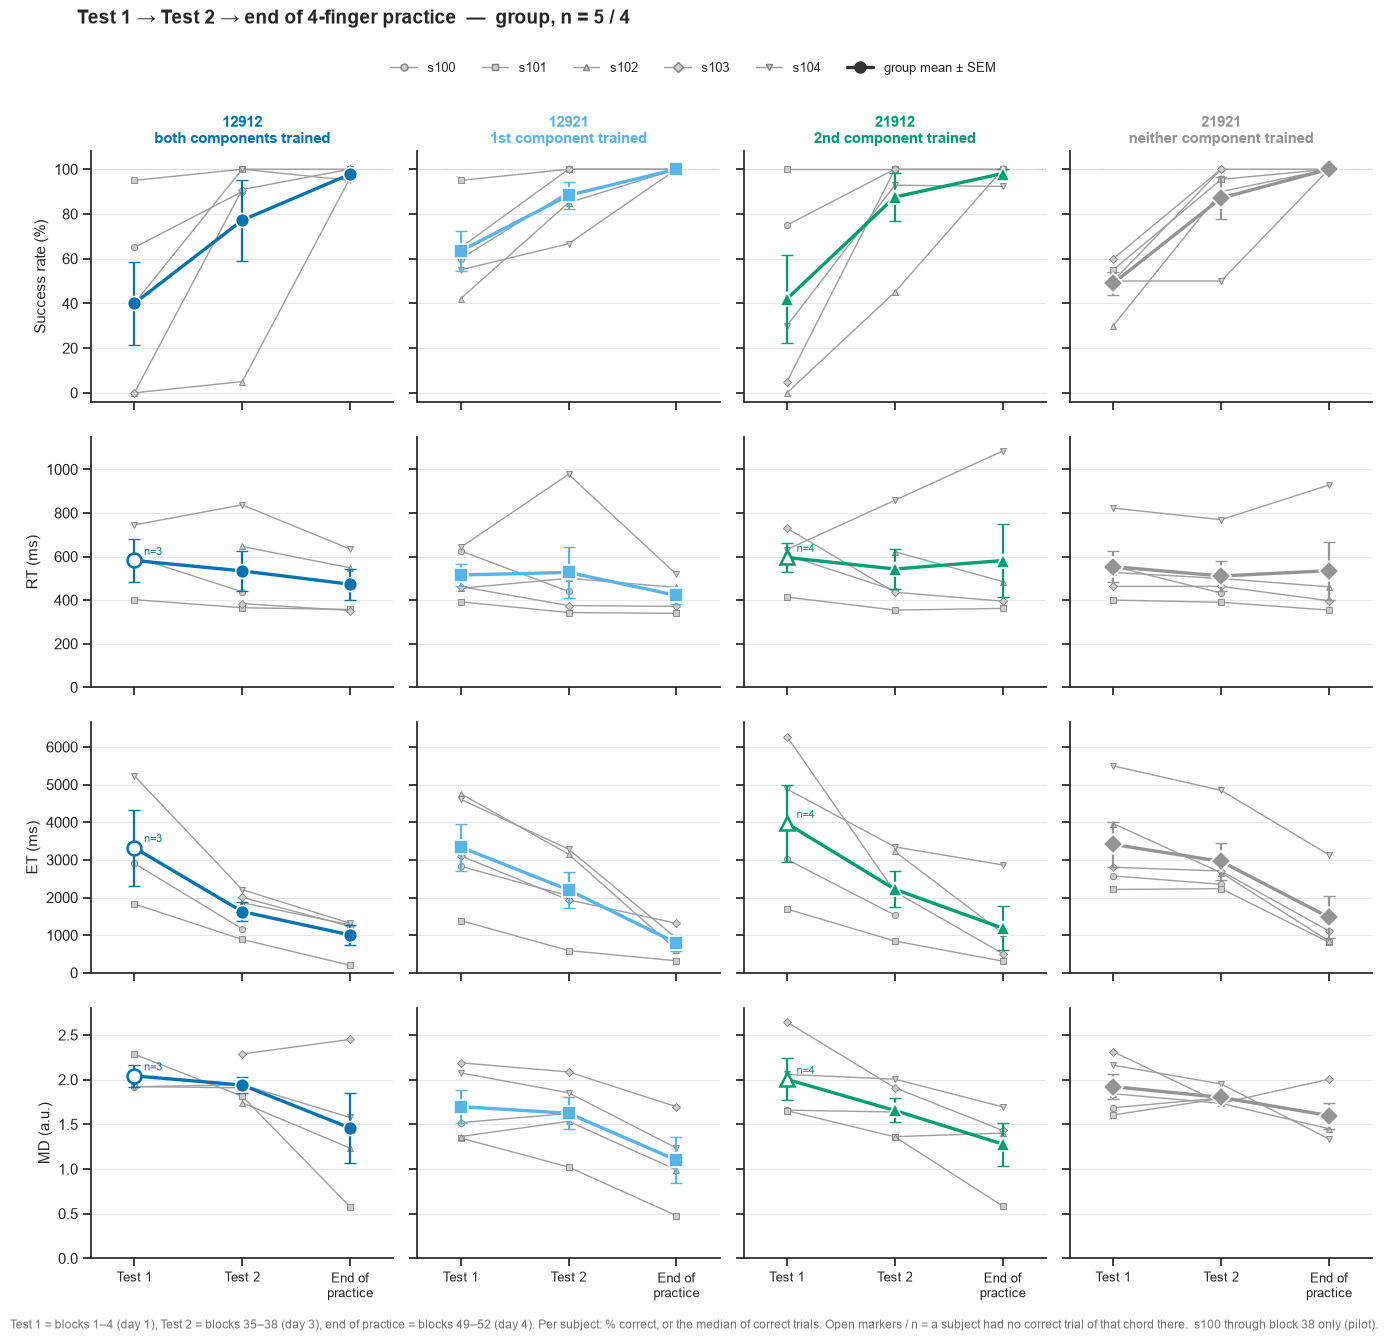

wrote figures/group/performance/05_tests_by_chord.png


In [5]:
last_4f = [s for s in SEGMENTS if s["kind"] == "4f"][-1]["blocks"]
END_BLOCKS = list(last_4f)[-4:]
PHASES = {"Test 1": list(TEST1_BLOCKS),
          "Test 2": list(TEST2_BLOCKS),
          f"End of\npractice": END_BLOCKS}
SUBJ_MARKER = dict(zip(SUBJECTS, ["o", "s", "^", "D", "v", "P", "X"]))
xs = np.arange(len(PHASES))

fig, axes = plt.subplots(len(MEASURES), len(TESTED), figsize=(14, 13.5),
                         sharex=True, sharey="row")
for r, meas in enumerate(MEASURES):
    row_top = 0.0      # shared y per row: the limit must cover every panel, not just the last
    for k, c in enumerate(TESTED):
        ax = axes[r, k]
        vals = pd.DataFrame({ph: per_subject(blocks, c, meas) for ph, blocks in PHASES.items()},
                            index=SUBJECTS)
        for sn, row in vals.iterrows():
            ax.plot(xs, row.values, color="0.62", lw=1, marker=SUBJ_MARKER[sn], ms=4.5,
                    mfc="0.8", mec="0.5", mew=.6, zorder=2)
        stats = [group(vals[ph].dropna(), blocks) for ph, blocks in PHASES.items()]
        m, e, n, full = map(np.array, zip(*stats))
        row_top = np.nanmax([row_top, np.nanmax(vals.values), np.nanmax(m + e)])
        ax.errorbar(xs, m, yerr=e, color=COLOR[c], lw=2.4, capsize=4, elinewidth=1.6, zorder=4)
        for x, mi, ni, fi in zip(xs, m, n, full):
            if ni:
                ax.plot(x, mi, marker=MARKER[c], ms=10, color=COLOR[c], zorder=5,
                        mfc=COLOR[c] if fi else "white",
                        mec="white" if fi else COLOR[c], mew=1.2 if fi else 1.8)
                if not fi:
                    ax.annotate(f"n={ni}", (x, mi), xytext=(7, 4), textcoords="offset points",
                                fontsize=8, color=COLOR[c])
        if meas["col"] == "trialPoint":
            ax.set_ylim(-4, 108)
            ax.axhline(100, color="0.8", lw=.8, ls=":", zorder=1)
        ax.grid(axis="y", color="0.91", lw=.8); ax.set_axisbelow(True)
        ax.set_xlim(-.4, len(PHASES) - .6)
        if r == 0:
            ax.set_title(LABEL[c].replace("  ", "\n", 1), fontsize=10.5, color=COLOR[c],
                         fontweight="bold")
        if k == 0:
            ax.set_ylabel(meas["short"], fontsize=11)
    if meas["col"] != "trialPoint":
        axes[r, 0].set_ylim(0, row_top * 1.06)

for ax in axes[-1]:
    ax.set_xticks(xs); ax.set_xticklabels(list(PHASES), fontsize=9.5)

handles = [Line2D([], [], color="0.62", lw=1, marker=SUBJ_MARKER[sn], ms=5, mfc="0.8",
                  mec="0.5", label=f"s{sn}") for sn in SUBJECTS]
handles.append(Line2D([], [], color="0.2", lw=2.4, marker="o", ms=8, label="group mean ± SEM"))
fig.legend(handles=handles, loc="upper center", ncol=len(handles), frameon=False,
           bbox_to_anchor=(.5, .955), fontsize=9.5)
fig.suptitle(f"Test 1 → Test 2 → end of 4-finger practice  —  group, n = {N_TXT}",
             fontsize=13.5, fontweight="bold", x=.06, ha="left", y=.985, color="0.15")
fig.text(.012, .008,
         f"Test 1 = blocks {min(TEST1_BLOCKS)}–{max(TEST1_BLOCKS)} (day 1), Test 2 = blocks "
         f"{min(TEST2_BLOCKS)}–{max(TEST2_BLOCKS)} (day 3), end of practice = blocks "
         f"{END_BLOCKS[0]}–{END_BLOCKS[-1]} (day 4). Per subject: % correct, or the median of "
         f"correct trials. Open markers / n = a subject had no correct trial of that chord there."
         + (f"  {SHORT_TXT} (pilot)." if SHORT else ""),
         fontsize=8.5, color="0.45", ha="left")
fig.subplots_adjust(left=.07, right=.985, top=.88, bottom=.06, hspace=.14, wspace=.08)
fig.savefig(FIG_DIR / "05_tests_by_chord.png", dpi=200, facecolor="white")
plt.show()
print(f"wrote {(FIG_DIR / '05_tests_by_chord.png').relative_to(ROOT)}")